The goal of this project is to regroup patient testimonies into clusters (or categories).
We were given a .csv file containing hundreds of testimonies for this exercise.

The different algorithm used are based on this documentation:
https://colab.research.google.com/drive/10jcxkl76JtUDWjHJJGjtITV4c-ducvAl#scrollTo=zaOU4LkIcbuc

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from collections import defaultdict, Counter
import joblib

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.cluster import KMeans, AgglomerativeClustering, HDBSCAN, DBSCAN, MiniBatchKMeans, SpectralClustering, BisectingKMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score


import warnings
warnings.filterwarnings("ignore", message="n_jobs value 1 overridden")

They are a few problems in the dataset given :

- No header : no first line to determine the name of the columns.
    - we can fix it by specifing the column's name when we read the csv.
- Missing values : color is missing in some rows.
    - replace missing values by default 0x000000 (white).

In [2]:
df = pd.read_csv("Student_Dataset.csv", delimiter=",", on_bad_lines="warn", names=["id", "color", "testimony"], engine='python', header=None)

def fix_row(row) -> pd.Series:
    values        = row.dropna().tolist()
    id_val        = values[0]
    testimony_val = values[-1]
    color_val     = values[1] if len(values) > 2 else "0x000000"
    return pd.Series([id_val, color_val, testimony_val], index=["id", "color", "testimony"])

df_fixed = df.apply(fix_row, axis=1)

df_fixed.info()
df_fixed.head()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1011 entries, 0 to 1010
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         1011 non-null   int64 
 1   color      1011 non-null   object
 2   testimony  1011 non-null   object
dtypes: int64(1), object(2)
memory usage: 23.8+ KB


,id,color,testimony
0,1,0x000000,On uneven paths the heel feels wobbly side‑to‑...
1,2,0x000000,"The feverish feeling eased, but I’m now breath..."
2,3,0x000000,"While working in the garden, I touched a metal..."
3,4,0x000000,A short sprint brought on a twinge in the midd...
4,5,0x000000,I accidentally left my hand on a hot mug for a...


The trick here is that the "read_csv" automaticly put the tesminonies in the "color" column. So we need to force the testimonies to go in the last column and repace the value in "color" by default 0x000000 (black).

We convert the values in the "testimony" column in str for easier manipulation later.

In [3]:
df_clean = df.dropna(subset=["testimony"]).copy()

corpus = df_clean["testimony"].astype(str).tolist()

We use a small function to change the color code (0x000000) to something usable for matplotlib (#000000).

In [4]:
def fix_color(c):
    if isinstance(c, str) and c.startswith("0x"):
        return "#" + c[2:]
    return "#000000"

colors = df_clean["color"].fillna("0x000000").apply(fix_color)

First we need to "embed" the text. It means to convert the sentences and the words into numerical objects.
It will also allow us to do more cleaning to :
    - elimate very frequent words
    - elimate very rare words
    - remove all "filling" words in english like pronouns


In [5]:
custom_stopwords = {'ache', 'aches', 'feel', 'feels', 'area', 'pain', '37'} # we remove some words that are not sepcific or discrimitave enough in this context

all_stopwords = list(ENGLISH_STOP_WORDS.union(custom_stopwords))

vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words=all_stopwords,
    max_df=0.6, # elimate the words that appear in more than 60% of the dataset
    min_df=0.01, # elimate the words that appear in less than 1% of the dataset
    ngram_range=(1, 2),
    sublinear_tf=True,
    max_features=5000
)

X = vectorizer.fit_transform(corpus)

print(vectorizer.get_feature_names_out())
print(X.shape)

['abdomen' 'ago' 'air' 'ankle' 'appear' 'appeared' 'appears' 'arm' 'arms'
 'avoid' 'bad' 'band' 'bathroom' 'bed' 'began' 'bending' 'better' 'big'
 'bit' 'blister' 'blisters' 'blocked' 'blood' 'blood pressure' 'blurs'
 'body' 'breath' 'breathe' 'breathing' 'bright' 'brings' 'bumps' 'burning'
 'calf' 'car' 'catch' 'catch breath' 'changed' 'chest' 'chest tight'
 'child' 'cleaning' 'clear' 'cold' 'congested' 'congestion' 'constant'
 'cough' 'coughing' 'couple' 'cup' 'day' 'days' 'deep' 'deep breath'
 'developed' 'didn' 'dizzy' 'doctor' 'doesn' 'don' 'drinking' 'dry'
 'dry cough' 'dull' 'ear' 'ears' 'eases' 'eat' 'edge' 'elbow' 'especially'
 'evening' 'experienced' 'eye' 'eyes' 'face' 'faint' 'family' 'fast'
 'fatigue' 'feeling' 'felt' 'fever' 'feverish' 'fine' 'fingers' 'flares'
 'flat' 'flickers' 'flight' 'flu' 'foot' 'forearm' 'forward' 'frequent'
 'frequently' 'gets' 'gets worse' 'getting' 'gives' 'going' 'got' 'groin'
 'gums' 'hair' 'hand' 'hands' 'happening' 'hard' 'haven' 'having' 'h

Singular Value Decomposition (SVD) + Normalization

In [6]:
svd = TruncatedSVD(n_components=300, random_state=42)
X_reduced = svd.fit_transform(X)

X_reduced = Normalizer().fit_transform(X_reduced)

We can't use directly Kmeans since we don't know the exact number of cluster we will have (instead of cluster you can imagine "categories" like *tooth aches*, *mental trouble*, *broken bone*...)
So we use a "silhouette score" for each k to determine which seems better

In [7]:
best_score = -1
best_k = None

for k in range(2, 10):
    model = KMeans(n_clusters=k, random_state=42)
    labels_tmp = model.fit_predict(X_reduced)

    score = silhouette_score(X_reduced, labels_tmp)

    if score > best_score:
        best_score = score
        best_k = k

    print(f"Best k: {best_k} with score {best_score}\n")

print(f"Final Best k: {best_k} with score {best_score}\n")

# the final model with the best k
model = KMeans(n_clusters=best_k, random_state=42)
labels = model.fit_predict(X_reduced)


Best k: 2 with score 0.01411185441423412

Best k: 3 with score 0.018060878555329226

Best k: 4 with score 0.023338327673049133

Best k: 5 with score 0.025432531516276616

Best k: 5 with score 0.025432531516276616

Best k: 5 with score 0.025432531516276616

Best k: 8 with score 0.030031567475190826

Best k: 9 with score 0.030988214278319635

Final Best k: 9 with score 0.030988214278319635



The silhouette score measures how well each data point fits within its cluster. The score is between 0.0 and 1.0. The greater the better.

A good silhouette score would be something around 0.5. You can imagine that a score of 0.03 is terrible (it is worst than random).
For the project we decided to push the analise a bit further to understand what is going on.

To have a better vision of the clusters created, we print the most frequent words in each cluster

In [8]:
terms = vectorizer.get_feature_names_out()
centroids = model.cluster_centers_

for i, center in enumerate(centroids):
    top_indices = center.argsort()[-10:][::-1]
    print([terms[j] for j in top_indices])

analyzer = vectorizer.build_analyzer()

for i in range(best_k):
    texts = [corpus[j] for j in range(len(labels)) if labels[j] == i]
    
    tokens = []
    for t in texts:
        tokens.extend(analyzer(t))
    
    common = Counter(tokens).most_common(10)
    print([w for w, _ in common])

['arm', 'abdomen', 'avoid', 'ankle', 'blister', 'air', 'arms', 'better', 'congestion', 'body']
['abdomen', 'appear', 'appears', 'air', 'began', 'bad', 'bending', 'avoid', 'bright', 'calf']
['abdomen', 'ankle', 'bed', 'air', 'ago', 'body', 'burning', 'began', 'bathroom', 'days']
['ago', 'abdomen', 'breathe', 'appears', 'blood pressure', 'bending', 'arms', 'blood', 'calf', 'elbow']
['abdomen', 'ankle', 'appeared', 'appear', 'ago', 'avoid', 'congested', 'cough', 'blurs', 'fever']
['abdomen', 'appears', 'arms', 'appeared', 'avoid', 'began', 'bit', 'flickers', 'blurs', 'evening']
['abdomen', 'bathroom', 'ankle', 'appear', 'arms', 'arm', 'band', 'big', 'air', 'appears']
['abdomen', 'blisters', 'appear', 'appeared', 'bad', 'cleaning', 'blood', 'arm', 'constant', 'fast']
['air', 'abdomen', 'ago', 'appeared', 'better', 'band', 'bathroom', 'catch', 'avoid', 'big']
['pressure', 'blood', 'blood pressure', 'doctor', 'told', 'high', 'didn', 'sugar', 'especially', 'chest']
['breath', 'deep', 'short',

We can see that the words are very similar in all the cluster. Which is not the expected result.

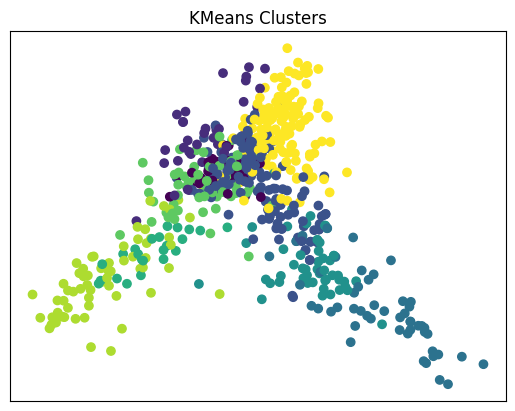

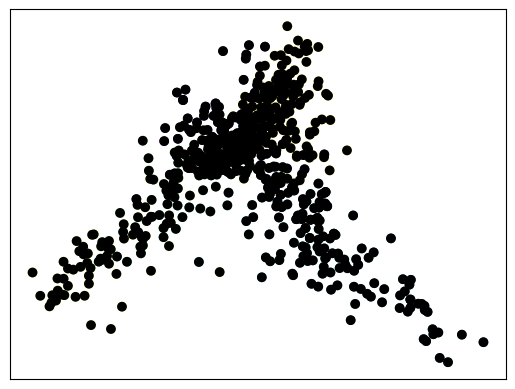

In [9]:
df_clean["cluster"] = labels

true_labels = LabelEncoder().fit_transform(df_clean["color"].fillna("unknown"))

ari = adjusted_rand_score(true_labels, df_clean["cluster"])

X_2d = PCA(n_components=2).fit_transform(X_reduced)


plt.figure() 
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=labels) 
plt.title("KMeans Clusters")
plt.xticks([])
plt.yticks([])
plt.show()

plt.figure() 
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=labels)
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=colors)
plt.xticks([])
plt.yticks([])
plt.show()

Since TF-IDF doesn't seem to match our expectation, we tried another embeding method with UMAP.

In [10]:
import umap

results = []

umap_model = umap.UMAP(
    n_components=20,
    n_neighbors=15,
    min_dist=0.1,
    metric='cosine',
    random_state=42
)

X_reduced = umap_model.fit_transform(X)

/home/martin-muller/Epitech tek2/G-AIA-400-NCY-4-1-cvrie-5/clustering_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


For the first part we will use models based on a *k* number of clusters (like Kmeans above).

So we created a function that will test a model given in parameter with different parameters for the umap. We will compare the silhouette scores of each and retrun the best one. It is like a "hand made" GridSearch

In [11]:
k_results = []

def umap_clustering_search(X, model_builder, model_name):
    best_score = -1
    best_params = None

    for n_comp in [10, 20, 50]:
        for n_neigh in [10, 15, 30]:
            for min_dist in [0.0, 0.1, 0.3]:

                umap_model = umap.UMAP( # we recreate the UMAP we different parameters each time
                    n_components=n_comp,
                    n_neighbors=n_neigh,
                    min_dist=min_dist,
                    metric='cosine',
                    random_state=42
                )

                X_reduced = umap_model.fit_transform(X)

                for k in range(2, 10): # like in the first test we try different k since we don't know the number of clusters before

                    model = model_builder(k)

                    labels = model.fit_predict(X_reduced)
                    score = silhouette_score(X_reduced, labels)

                    k_results.append({
                        "model": model_name,
                        "n_components": n_comp,
                        "n_neighbors": n_neigh,
                        "min_dist": min_dist,
                        "k": k,
                        "score": score
                    })

                    if score > best_score:
                        best_score = score
                        best_params = (n_comp, n_neigh, min_dist, k)

    print(f"Best parameters for {model_name} => score: {best_score} with {best_params}")
    return best_params, best_score, k_results

# Kmeans

Partitions data into k clusters by minimizing the distance between points and their cluster centroid.

scikit-learn doc : https://scikit-learn.org/stable/modules/clustering.html#k-means

In [12]:
best_params, best_score, k_results = umap_clustering_search(
    X,
    lambda k: KMeans(n_clusters=k, random_state=42),
    "KMeans"
)

best_params, best_score, k_results = umap_clustering_search(
    X_reduced, # We also tried combining the UMAP with the SVD and Normalizer
    lambda k: KMeans(n_clusters=k, random_state=42),
    "KMeans"
)

Best parameters for KMeans => score: 0.5044174194335938 with (10, 10, 0.0, 9)
Best parameters for KMeans => score: 0.7497456669807434 with (20, 10, 0.0, 9)


As you can see, we get much better results with the SVD and Normalizer. We will be using the X_reduced for the rest of the tests.

# Agglomerative search

A hierarchical method that starts with each point as its own cluster and progressively merges them.

scikit-learn doc : https://scikit-learn.org/stable/modules/clustering.html#hierarchical-clustering

In [13]:
best_params, best_score, k_results = umap_clustering_search(
    X_reduced,
    lambda k: AgglomerativeClustering(n_clusters=k),
    "Agglomerative"
)

Best parameters for Agglomerative => score: 0.7675422430038452 with (10, 10, 0.0, 9)


# Mini Batch KMeans

A faster version of KMeans using small random batches of data.

scikit-learn doc : https://scikit-learn.org/stable/modules/clustering.html#mini-batch-k-means

In [14]:
best_params, best_score, k_results = umap_clustering_search(
    X_reduced,
    lambda k: MiniBatchKMeans(n_clusters=k, random_state=42),
    "MiniBatchKMeans"
)

Best parameters for MiniBatchKMeans => score: 0.7743406295776367 with (20, 15, 0.0, 8)


# BisectingKMeans

A hierarchical variant of KMeans that repeatedly splits clusters into two.

scikit-learn doc : https://scikit-learn.org/stable/modules/clustering.html#bisecting-k-means

In [15]:
best_params, best_score, k_results = umap_clustering_search(
    X_reduced,
    lambda k: BisectingKMeans(n_clusters=k, random_state=42),
    "BisectingKMeans"
)

Best parameters for BisectingKMeans => score: 0.7450407147407532 with (20, 15, 0.0, 9)


# Spectral Clustering

Uses graph-based similarity between points and performs clustering in a transformed space.

scikit-learn doc : https://scikit-learn.org/stable/modules/clustering.html#spectral-clustering

In [16]:
best_params, best_score, k_results = umap_clustering_search(
    X, # SVD and Normalizer don't work with the Spectral clustering so we use X
    lambda k: SpectralClustering(n_clusters=k, assign_labels='kmeans'),
    "Spectral"
)

Best parameters for Spectral => score: 0.5090886950492859 with (10, 10, 0.0, 9)


To compare the results of the different models tested above, we store the df_k_results into a dataframe that we sort with the score.\
Then we recreate the final model with the best UMAP and parameters.\
Finally, we plot a graph to visualize the clusters created.

model           MiniBatchKMeans
n_components                 20
n_neighbors                  15
min_dist                    0.0
k                             8
score                  0.774341
Name: 750, dtype: object


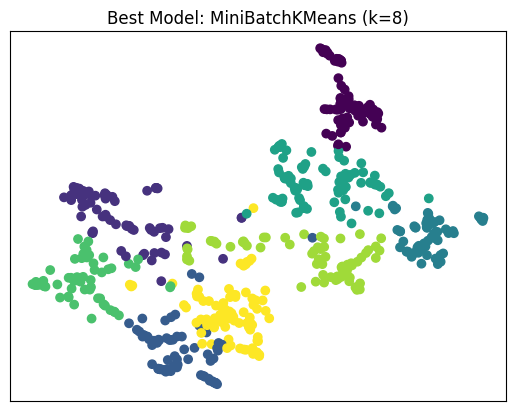

In [17]:
df_k_results = pd.DataFrame(k_results)

best_row = df_k_results.sort_values("score", ascending=False).iloc[0]
print(best_row)

best_model_name = best_row["model"]
best_k = int(best_row["k"])
n_comp = int(best_row["n_components"])
n_neigh = int(best_row["n_neighbors"])
min_dist = float(best_row["min_dist"])

umap_best = umap.UMAP(
    n_components=n_comp,
    n_neighbors=n_neigh,
    min_dist=min_dist,
    metric='cosine',
    random_state=42
)

X_best = umap_best.fit_transform(X)

# rebuild model
model_dict = {
    "KMeans": lambda k: KMeans(n_clusters=k, random_state=42),
    "Agglomerative": lambda k: AgglomerativeClustering(n_clusters=k),
    "MiniBatchKMeans": lambda k: MiniBatchKMeans(n_clusters=k, random_state=42),
    "BisectingKMeans": lambda k: BisectingKMeans(n_clusters=k, random_state=42),
    "Spectral": lambda k: SpectralClustering(n_clusters=k, assign_labels='kmeans')
}

model = model_dict[best_model_name](best_k)
labels_best = model.fit_predict(X_best)

umap_2d = umap.UMAP( # we build a 2D UMAP to vizualise the results in a graph
    n_components=2,
    n_neighbors=n_neigh,
    min_dist=min_dist,
    metric='cosine',
    random_state=42
)

X_2d = umap_2d.fit_transform(X)

plt.figure()
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=labels_best)
plt.title(f"Best Model: {best_model_name} (k={best_k})")
plt.xticks([])
plt.yticks([])
plt.show()

Since UMAP dimensions are not directly interpretable, the axes were removed to emphasize the cluster structure rather than arbitrary coordinate values.\
The different colors of the graph represent the clusters.\
After the tests, the Mini Batches K Means seems to be the best model.


We save our final model with the dump function from joblib.

In [18]:
joblib.dump({
    "umap": umap_best,
    "model": model,
    "params": best_row.to_dict()
}, "CVRIE_PATIENT_TESTIMONY_CLUSTERING.pkl")

['CVRIE_PATIENT_TESTIMONY_CLUSTERING.pkl']

We wanted to push the test further with other models in the scikit-learn library.

For this one, we use HDBSCAN. Since it doesn't use a *k* parameter, we need to change our function to correspond to the HDBSCAN model parameters

# HDBSCAN

Density-based clustering that automatically determines the number of clusters.

scikit-learn doc : https://scikit-learn.org/stable/modules/clustering.html#hdbscan

In [19]:
hdbscan_results = []

def umap_hdbscan_search(X):
    best_score = -1
    best_params = None

    for n_comp in [10, 20, 50]:
        for n_neigh in [10, 15, 30]:
            for min_dist in [0.0, 0.1, 0.3]:

                umap_model = umap.UMAP(
                    n_components=n_comp,
                    n_neighbors=n_neigh,
                    min_dist=min_dist,
                    metric='cosine',
                    random_state=42
                )

                X_reduced = umap_model.fit_transform(X)

                for min_cluster_size in [5, 10, 20]: # this the part that differs from the previous function

                    model = HDBSCAN(
                        copy=True,
                        min_cluster_size=min_cluster_size
                    )

                    labels = model.fit_predict(X_reduced)

                    if len(set(labels)) <= 1:
                        continue

                    score = silhouette_score(X_reduced, labels)

                    hdbscan_results.append({ 
                        "model": "HDBSCAN",
                        "n_components": n_comp,
                        "n_neighbors": n_neigh,
                        "min_dist": min_dist,
                        "min_cluster_size": min_cluster_size,
                        "score": score
                    })

                    if score > best_score:
                        best_score = score
                        best_params = (n_comp, n_neigh, min_dist, min_cluster_size)

    print(f"Best HDBSCAN => score: {best_score}, params: {best_params}")


# The function is not meant to be generic so we don't have a "model" parameter
umap_hdbscan_search(X_reduced)

Best HDBSCAN => score: 0.7455299496650696, params: (10, 10, 0.0, 10)


Top 10 HDBSCAN results:
      model  n_components  n_neighbors  min_dist  min_cluster_size     score
1   HDBSCAN            10           10       0.0                10  0.745530
55  HDBSCAN            50           10       0.0                10  0.732266
11  HDBSCAN            10           15       0.0                20  0.729854
38  HDBSCAN            20           15       0.0                20  0.721205
29  HDBSCAN            20           10       0.0                20  0.707764
2   HDBSCAN            10           10       0.0                20  0.706255
37  HDBSCAN            20           15       0.0                10  0.697039
56  HDBSCAN            50           10       0.0                20  0.696845
32  HDBSCAN            20           10       0.1                20  0.694817
41  HDBSCAN            20           15       0.1                20  0.691662


/home/martin-muller/Epitech tek2/G-AIA-400-NCY-4-1-cvrie-5/clustering_env/lib/python3.12/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


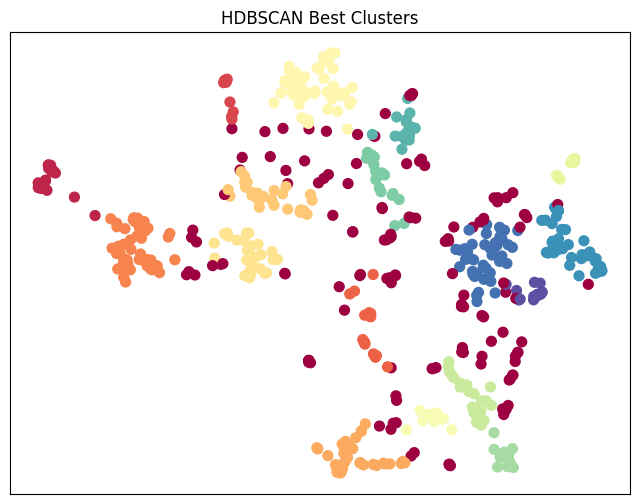

In [20]:
hdbscan_df_results = pd.DataFrame(hdbscan_results)
best_row = hdbscan_df_results.sort_values("score", ascending=False).iloc[0]  # top row

print("Top 10 HDBSCAN results:")
print(hdbscan_df_results.sort_values("score", ascending=False).head(10))

# Extract best parameters
n_components = int(best_row["n_components"])
n_neighbors = int(best_row["n_neighbors"])
min_dist = float(best_row["min_dist"])
min_cluster_size = int(best_row["min_cluster_size"])

# Reduce to 2D for plotting
umap_2d = umap.UMAP(
    n_components=2,
    n_neighbors=n_neighbors,
    min_dist=min_dist,
    metric='cosine',
    random_state=42
)
X_2d = umap_2d.fit_transform(X)

# Fit HDBSCAN with best params
best_hdbscan = HDBSCAN(min_cluster_size=min_cluster_size)
labels_hdbscan = best_hdbscan.fit_predict(X_2d)

plt.figure(figsize=(8, 6))
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=labels_hdbscan, cmap='Spectral', s=50)
plt.title("HDBSCAN Best Clusters")
plt.xticks([])
plt.yticks([])
plt.show()

interpretation

# DBSCAN

Groups points based on density (regions with many nearby points).

scikit-learn doc : https://scikit-learn.org/stable/modules/clustering.html#dbscan

In [21]:
dbscan_results = []

def umap_dbscan_search(X):
    best_score = -1
    best_params = None

    for n_comp in [10, 20, 50]:
        for n_neigh in [10, 15, 30]:
            for min_dist in [0.0, 0.1, 0.3]:

                umap_model = umap.UMAP(
                    n_components=n_comp,
                    n_neighbors=n_neigh,
                    min_dist=min_dist,
                    metric='cosine',
                    random_state=42
                )

                X_reduced = umap_model.fit_transform(X)

                for eps in [0.1, 0.3, 0.5, 0.7, 1.0]:
                    for min_samples in [5, 10, 20]:

                        model = DBSCAN(
                            eps=eps,
                            min_samples=min_samples,
                            metric='euclidean'
                        )

                        labels = model.fit_predict(X_reduced)

                        # Ignore if all points are in one cluster or all are noise (-1)
                        if len(set(labels)) <= 1 or (set(labels) == {-1}):
                            continue

                        score = silhouette_score(X_reduced, labels)

                        dbscan_results.append({
                            "model": "DBSCAN",
                            "n_components": n_comp,
                            "n_neighbors": n_neigh,
                            "min_dist": min_dist,
                            "eps": eps,
                            "min_samples": min_samples,
                            "score": score
                        })

                        if score > best_score:
                            best_score = score
                            best_params = (n_comp, n_neigh, min_dist, eps, min_samples)

    print(f"Best DBSCAN => score: {best_score}, params: {best_params}")

umap_dbscan_search(X_reduced)

Best DBSCAN => score: 0.7688547968864441, params: (10, 15, 0.0, 1.0, 5)


Top 10 DBSCAN results:
      model  n_components  n_neighbors  min_dist  eps  min_samples     score
47   DBSCAN            10           15       0.0  1.0            5  0.768855
48   DBSCAN            10           15       0.0  1.0           10  0.768855
4    DBSCAN            10           10       0.0  0.5            5  0.726380
132  DBSCAN            20           10       0.1  1.0            5  0.725746
5    DBSCAN            10           10       0.0  0.5           10  0.725398
85   DBSCAN            10           30       0.0  1.0           10  0.725273
84   DBSCAN            10           30       0.0  1.0            5  0.725273
298  DBSCAN            50           30       0.0  1.0           10  0.719769
297  DBSCAN            50           30       0.0  1.0            5  0.719769
133  DBSCAN            20           10       0.1  1.0           10  0.716091


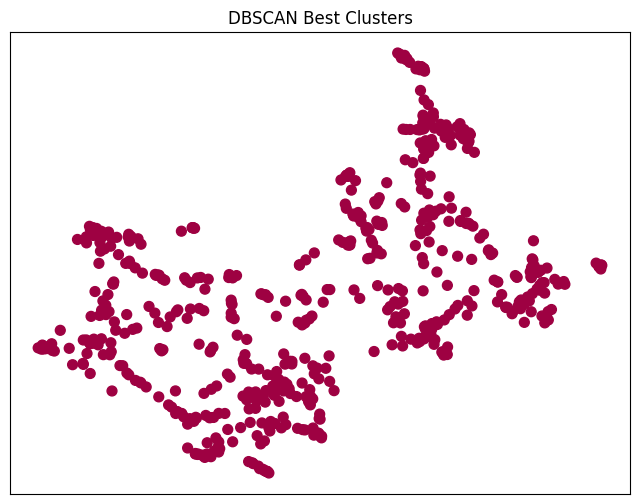

In [22]:
dbscan_df_results = pd.DataFrame(dbscan_results)
best_row = dbscan_df_results.sort_values("score", ascending=False).iloc[0]

print("Top 10 DBSCAN results:")
print(dbscan_df_results.sort_values("score", ascending=False).head(10))

# Extract best parameters
n_components = int(best_row["n_components"])
n_neighbors = int(best_row["n_neighbors"])
min_dist = float(best_row["min_dist"])
eps = float(best_row["eps"])
min_samples = int(best_row["min_samples"])

# Reduce to 2D for plotting
umap_2d = umap.UMAP(
    n_components=2,
    n_neighbors=n_neighbors,
    min_dist=min_dist,
    metric='cosine',
    random_state=42
)
X_2d = umap_2d.fit_transform(X)

# Fit DBSCAN with best params
best_dbscan = DBSCAN(eps=eps, min_samples=min_samples)
labels_dbscan = best_dbscan.fit_predict(X_2d)

plt.figure(figsize=(8, 6))
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=labels_dbscan, cmap='Spectral', s=50)
plt.title("DBSCAN Best Clusters")
plt.xticks([])
plt.yticks([])
plt.show()

Since the results are not better than the models above we didn't save a new model.